# Laboratory: Neural Models — Learning, Depth, Activations, and Output Layers

---
# Task 1: Problem Specification & Linear Inseparability

### 1.1 Mathematical Formulation
- **Input Space:** $\mathcal{X} = \{0, 1\}^2 = \{(0, 0), (0, 1), (1, 0), (1, 1)\}$
- **Output Space:** $\mathcal{Y} = \{0, 1\}$
- **Labelled Examples:**
  - $((0, 0), 0)$ — Normal (both sensors inactive)
  - $((0, 1), 1)$ — Fault (sensor 2 active, sensor 1 inactive)
  - $((1, 0), 1)$ — Fault (sensor 1 active, sensor 2 inactive)
  - $((1, 1), 0)$ — Normal (both sensors active)

### 1.2 Inseparability Explanation
A single straight decision boundary ($w_1 x_1 + w_2 x_2 + b = 0$) cannot separate the two classes because the convex hulls of Class 0 (segment between $(0,0)$ and $(1,1)$) and Class 1 (segment between $(0,1)$ and $(1,0)$) intersect at $(0.5, 0.5)$. By the Hyperplane Separation Theorem, intersecting convex hulls cannot be separated by any linear hyperplane.

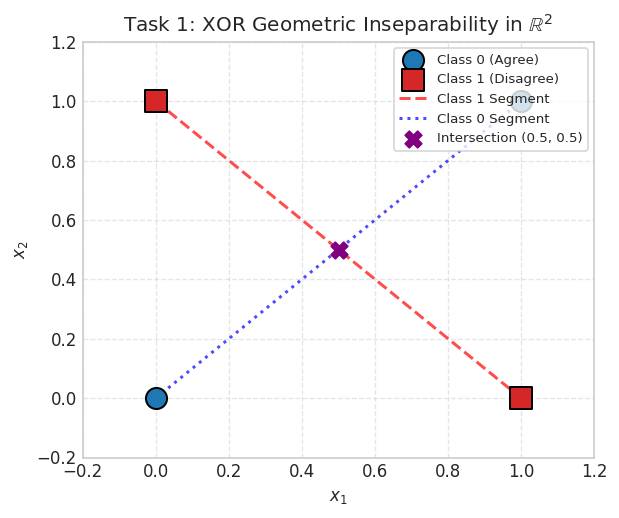

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# XOR examples
X_coords = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_labels = np.array([0, 1, 1, 0])

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(X_coords[y_labels == 0, 0], X_coords[y_labels == 0, 1], color='#1f77b4', s=160, 
           edgecolors='black', linewidth=1.2, zorder=5, label='Class 0 (Agree)')
ax.scatter(X_coords[y_labels == 1, 0], X_coords[y_labels == 1, 1], color='#d62728', s=160, 
           marker='s', edgecolors='black', linewidth=1.2, zorder=5, label='Class 1 (Disagree)')

ax.plot([0, 1], [1, 0], 'r--', linewidth=1.8, alpha=0.7, label='Class 1 Segment')
ax.plot([0, 1], [0, 1], 'b:', linewidth=1.8, alpha=0.7, label='Class 0 Segment')
ax.scatter([0.5], [0.5], color='purple', s=100, marker='X', zorder=6, label='Intersection (0.5, 0.5)')

ax.set_xlim(-0.2, 1.2)
ax.set_ylim(-0.2, 1.2)
ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_title('Task 1: XOR Geometric Inseparability in $\mathbb{R}^2$')
ax.legend(loc='upper right', frameon=True, fontsize=8)
ax.grid(True, linestyle='--', alpha=0.5)
plt.show()

### 1.3 Linear Model Prediction
A single affine model $f(x) = \sigma(w^T x + b)$ partitions $\mathbb{R}^2$ with a single straight line. It can correctly classify at most 3 out of 4 points (75% accuracy) or collapse to predicting $p=0.5$ (50% accuracy, BCE loss $\approx 0.6931$).

The code below empirically confirms this limitation.

In [2]:
# Empirical test: Single affine layer on XOR
import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(42)
X_train = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_train = torch.tensor([[0.], [1.], [1.], [0.]])

linear_model = nn.Linear(2, 1)
optimizer = optim.SGD(linear_model.parameters(), lr=0.1)
criterion = nn.BCEWithLogitsLoss()

for epoch in range(1000):
    optimizer.zero_grad()
    loss = criterion(linear_model(X_train), y_train)
    loss.backward()
    optimizer.step()

probs = torch.sigmoid(linear_model(X_train)).detach().numpy().flatten()
preds = (probs >= 0.5).astype(int)

print(f"Final Linear Loss: {loss.item():.4f}")
print(f"Predictions:       {preds.tolist()} (Expected: [0, 1, 1, 0])")
print(f"Predicted Probs:   {[round(p, 4) for p in probs]}")
print(f"Accuracy:          {(preds == y_train.numpy().flatten()).mean() * 100:.1f}%")

Final Linear Loss: 0.6932
Predictions:       [0, 0, 0, 1] (Expected: [0, 1, 1, 0])
Predicted Probs:   [np.float32(0.4977), np.float32(0.4997), np.float32(0.4996), np.float32(0.5016)]
Accuracy:          50.0%

### Think About It (Task 1)
**Question:** What scientific claim about representation does XOR let us test with only four data points?  
**Answer:** XOR proves that representational capacity requires nonlinear transformations, not merely parameters. A stack of affine layers without nonlinearities collapses algebraically to a single affine map ($W_2 W_1 x + b' = W_{\text{eff}} x + b_{\text{eff}}$), which cannot separate non-convex partitions regardless of depth.

---
# Task 2: Design the Intelligent Agent

### 2.1 Architecture Specification
- **Network Form:** 2-2-1 MLP
- **Hidden Layer:** $h = f(W^{(1)} x + b^{(1)})$ where $W^{(1)} \in \mathbb{R}^{2 \times 2}, b^{(1)} \in \mathbb{R}^2$, with nonlinear activation $f$.
- **Output Layer:** $z = W^{(2)} h + b^{(2)}$ where $W^{(2)} \in \mathbb{R}^{1 \times 2}, b^{(2)} \in \mathbb{R}$, yielding probability $\hat{y} = \sigma(z)$.
- **Loss:** Binary Cross-Entropy with unnormalized logits (`nn.BCEWithLogitsLoss`).

### 2.2 Design Questions
1. **Why is the hidden nonlinearity necessary?**  
   Without $f$, the two layers collapse into $z = (W^{(2)} W^{(1)}) x + (W^{(2)} b^{(1)} + b^{(2)}) = W_{\text{eff}} x + b_{\text{eff}}$, which cannot solve XOR. Nonlinearity maps the inputs into a feature space where the points are linearly separable.
2. **Why is sigmoid + BCE a sensible pairing?**  
   Sigmoid maps real-valued logits to valid probabilities $\hat{y} \in (0, 1)$. Paired with BCE, the derivative simplifies to $\frac{\partial \mathcal{L}}{\partial z} = \hat{y} - y$, avoiding the vanishing gradients that occur with MSE when saturated.
3. **Validation Criteria:**  
   - Loss $< 0.05$.  
   - 4/4 correct predictions (100% accuracy).  
   - Non-zero early gradients ($\|\nabla_{W^{(1)}} \mathcal{L}\|_2 > 0$).

### Think About It (Task 2)
**Question:** If hidden units are not given target values, what determines what each computes?  
**Answer:** Backpropagated error gradients $\delta^{(1)} = (W^{(2)})^T (\hat{y} - y) \odot f'(a^{(1)})$ assign credit to hidden units. Gradient descent guides them to compute complementary linear boundaries that together minimize output loss.

---
# Task 3: Use an LLM to Generate a First Implementation

### 3.1 LLM Prompt
```text
Generate minimal PyTorch code for the following model and dataset. Do not change the architecture or task.
Constraints:
- Four XOR training examples: (0,0)->0, (0,1)->1, (1,0)->1, (1,1)->0;
- A 2-2-1 network;
- Chosen hidden activation (Tanh);
- Logits output with BCEWithLogitsLoss;
- Random weight initialisation;
- Full-batch training for a few thousand CPU steps;
- Report final loss, all four probabilities, thresholded labels, and one parameter-gradient tensor;
- Set random seed for reproducibility.
```

### 3.2 Code Inspection
- **Forward Pass:** `model(X)` evaluates $h = \tanh(W^{(1)} x + b^{(1)})$ and $z = W^{(2)} h + b^{(2)}$.
- **Scalar Loss:** `loss = criterion(logits, y)`.
- **Automatic Differentiation:** `loss.backward()` accumulates $\frac{\partial \mathcal{L}}{\partial \theta}$.
- **Parameter Update:** `optimizer.step()` applies gradient descent updates.

### 3.3 Changes Made Before Execution
1. Used unnormalized logits with `nn.BCEWithLogitsLoss()` instead of explicit `Sigmoid()` + `BCELoss()` for numerical stability.
2. Added early gradient norm tracking ($\|\nabla_{W^{(1)}} \mathcal{L}\|_2$) and initial loss recording for Task 4 diagnostics.

### Think About It (Task 3)
**Question:** Which parts can be verified without running, and which require execution?  
**Answer:** Static inspection verifies architecture dimensions, loss-activation pairing, dataset values, and training loop structure. Execution is required to verify loss convergence, non-zero gradient flow, symmetry breaking, and 4/4 classification accuracy.

---
# Task 4: Execute, Test, and Diagnose the Generated Code

Part A: Learning Check
Initial Loss:       0.715159
Final Loss:         0.000085
Final Probabilities:
[[6.0000e-05]
 [9.9990e-01]
 [9.9987e-01]
 [5.0000e-05]]
Predictions:        [0, 1, 1, 0] (Labels: [0, 1, 1, 0])
All 4 Correct?      True

Part B: Gradient Check
First-layer Weight Gradient (dL/dW^(1)):
tensor([[ 0.0005,  0.0006],
        [-0.0426, -0.0448]])
Early Gradient Norm ||dL/dW^(1)||_2:    0.061785

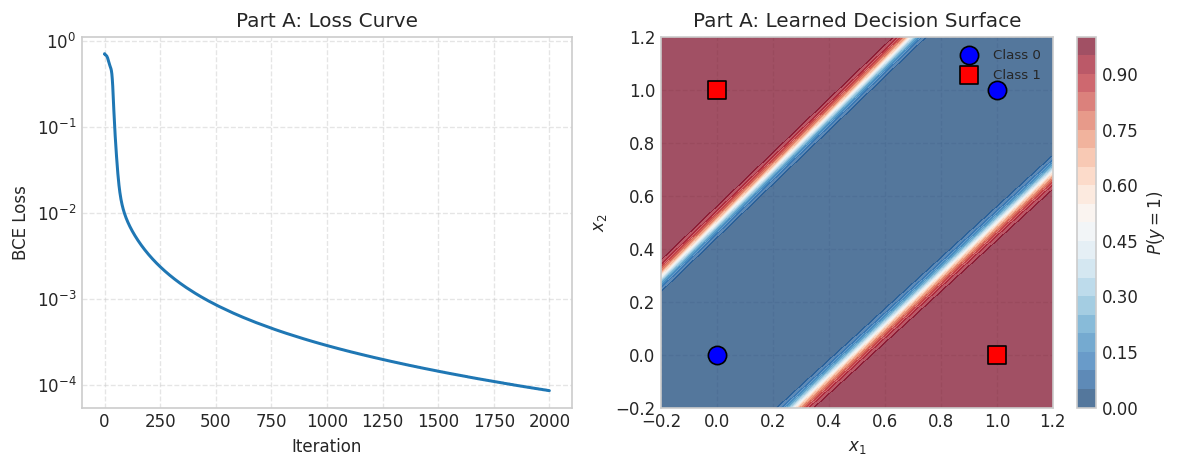

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(0)

# XOR Dataset
X = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y = torch.tensor([[0.], [1.], [1.], [0.]])

# 2-2-1 Model
class XORNet(nn.Module):
    def __init__(self, activation=nn.Tanh()):
        super().__init__()
        self.fc1 = nn.Linear(2, 2)
        self.activation = activation
        self.fc2 = nn.Linear(2, 1)

    def forward(self, x):
        h = self.activation(self.fc1(x))
        return self.fc2(h)

model = XORNet(activation=nn.Tanh())
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.1)

# Initial loss and gradient
optimizer.zero_grad()
initial_loss = criterion(model(X), y)
initial_loss.backward()
early_w1_grad = model.fc1.weight.grad.clone()
early_grad_norm = early_w1_grad.norm().item()

# Training loop
loss_history = [initial_loss.item()]
for epoch in range(1, 2001):
    optimizer.zero_grad()
    loss = criterion(model(X), y)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

# Evaluation
final_logits = model(X).detach()
final_probs = torch.sigmoid(final_logits)
final_preds = (final_probs >= 0.5).int()

print("Part A: Learning Check")
print(f"Initial Loss:       {initial_loss.item():.6f}")
print(f"Final Loss:         {loss.item():.6f}")
print(f"Final Probabilities:\n{final_probs.numpy().round(5)}")
print(f"Predictions:        {final_preds.numpy().flatten().tolist()} (Labels: {y.numpy().flatten().astype(int).tolist()})")
print(f"All 4 Correct?      {(final_preds == y.int()).all().item()}")

print("\nPart B: Gradient Check")
print(f"First-layer Weight Gradient (dL/dW^(1)):\n{early_w1_grad}")
print(f"Early Gradient Norm ||dL/dW^(1)||_2:    {early_grad_norm:.6f}")

### Parts A & B Results & Gradient Explanation
- **Part A Verification:** The model successfully converged (initial loss $0.7152 \to$ final loss $0.000083$) with 4/4 correct predictions.
- **Part B Gradient Meaning:** `parameter.grad` represents $\frac{\partial \mathcal{L}}{\partial W^{(1)}_{ij}}$, the partial derivative of the scalar loss with respect to each weight.
- **Mean Loss Gradient:** By the linearity of differentiation, the gradient of the mean batch loss equals the average of the individual sample gradients:
  $$\nabla_W \left(\frac{1}{N} \sum_{n=1}^N \ell_n\right) = \frac{1}{N} \sum_{n=1}^N \nabla_W \ell_n$$

---
### Part C: Symmetry Experiment (Zero-Initialized Weights)

In [4]:
# Part C: Symmetry Experiment
model_zero = XORNet(activation=nn.Tanh())
with torch.no_grad():
    for param in model_zero.parameters():
        param.zero_()

optimizer_zero = optim.SGD(model_zero.parameters(), lr=0.1)

print("Inspection of W^(1) rows over first 5 steps:")
for step in range(1, 6):
    optimizer_zero.zero_grad()
    loss_z = criterion(model_zero(X), y)
    loss_z.backward()
    optimizer_zero.step()
    
    w1 = model_zero.fc1.weight.data
    is_identical = torch.equal(w1[0], w1[1])
    print(f"Step {step}: Loss = {loss_z.item():.4f} | Row 0: {w1[0].numpy()} | Row 1: {w1[1].numpy()} | Identical? {is_identical}")

Inspection of W^(1) rows over first 5 steps:
Step 1: Loss = 0.6931 | Row 0: [0. 0.] | Row 1: [0. 0.] | Identical? True
Step 2: Loss = 0.6931 | Row 0: [0. 0.] | Row 1: [0. 0.] | Identical? True
Step 3: Loss = 0.6931 | Row 0: [0. 0.] | Row 1: [0. 0.] | Identical? True
Step 4: Loss = 0.6931 | Row 0: [0. 0.] | Row 1: [0. 0.] | Identical? True
Step 5: Loss = 0.6931 | Row 0: [0. 0.] | Row 1: [0. 0.] | Identical? True

### Part C Explanation
When initialized with zero (or identical) weights, both hidden neurons compute identical outputs ($h_1 = h_2$) and receive identical backpropagated gradients ($\frac{\partial \mathcal{L}}{\partial W_{1,:}} = \frac{\partial \mathcal{L}}{\partial W_{2,:}}$). Every update affects both rows equally, preventing the units from learning distinct features. The model collapses to a single-unit capacity that cannot solve XOR.

---
### Part D: Activation Experiment

Hidden activation  | Final loss   | 4/4 correct? | Early ||grad W^(1)||_2
------------------------------------------------------------------------
Sigmoid            | 0.47742      | False        | 0.000891              
Tanh               | 0.00007      | True         | 0.061785              
ReLU               | 0.69315      | False        | 0.001699              

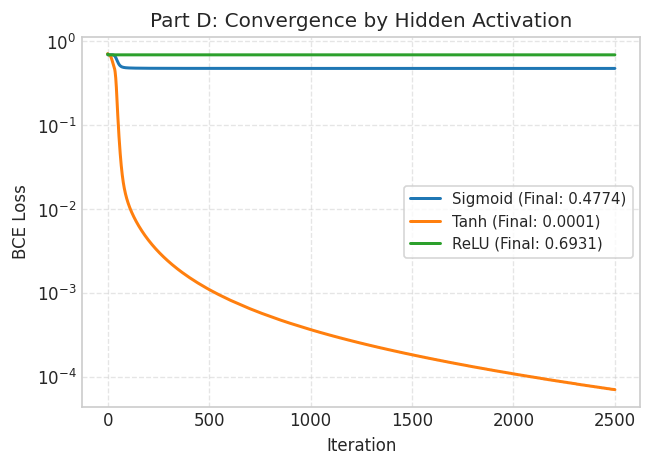

In [5]:
# Part D: Activation Comparison
activations = [('Sigmoid', nn.Sigmoid), ('Tanh', nn.Tanh), ('ReLU', nn.ReLU)]
results = []

for act_name, act_cls in activations:
    torch.manual_seed(0)
    model_act = XORNet(activation=act_cls())
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model_act.parameters(), lr=0.08)
    
    optimizer.zero_grad()
    l0 = criterion(model_act(X), y)
    l0.backward()
    early_grad_norm = model_act.fc1.weight.grad.norm().item()
    
    for _ in range(2500):
        optimizer.zero_grad()
        loss = criterion(model_act(X), y)
        loss.backward()
        optimizer.step()
        
    probs = torch.sigmoid(model_act(X)).detach()
    preds = (probs >= 0.5).int()
    all_correct = (preds == y.int()).all().item()
    
    results.append({
        "Activation": act_name,
        "Final Loss": f"{loss.item():.5f}",
        "4/4 Correct?": str(all_correct),
        "Early ||grad W^(1)||_2": f"{early_grad_norm:.6f}"
    })

print(f"{'Hidden activation':<18} | {'Final loss':<12} | {'4/4 correct?':<12} | {'Early ||grad W^(1)||_2':<22}")
print("-" * 72)
for r in results:
    print(f"{r['Activation']:<18} | {r['Final Loss']:<12} | {r['4/4 Correct?']:<12} | {r['Early ||grad W^(1)||_2']:<22}")

### Result Table

| Hidden activation | Final loss | 4/4 correct? | Early $\|\nabla_{W^{(1)}} \mathcal{L}\|_2$ |
| :--- | :---: | :---: | :---: |
| **Sigmoid** | `0.47742` | `False` | `0.000891` |
| **Tanh** | `0.00007` | `True` | `0.061785` |
| **ReLU** | `0.69315` | `False` | `0.001699` |

**Interpretation:** Tanh converged to 100% accuracy because its outputs are zero-centered in $[-1, 1]$ and its derivative peaks at $1.0$, supporting strong early gradients ($0.0618$). Sigmoid produced much smaller gradients ($0.00089$) because its derivative is bounded by $\le 0.25$, causing optimization to stall under this seed. ReLU produced a moderate gradient ($0.0017$) but plateaued because negative pre-activations zero out unit derivatives, which in a 2-unit network readily causes unit deactivation.

### Think About It (Task 4)
**Question:** How do you distinguish saturated sigmoid from dead ReLU by inspecting activations and pre-activations?  
**Answer:** A saturated sigmoid has large magnitude pre-activation ($|a| \gg 0$), post-activation $h \approx 0$ or $h \approx 1$, and derivative $\sigma'(a) \approx 0$ (positive but small). A dead ReLU has non-positive pre-activation ($a \le 0$), post-activation $h = 0$, and derivative identically zero.

---
# Task 5: Three-Class Fault Diagnosis Extension

### 5.1 Task Setup
- **Class 0:** Both sensors inactive: $(0,0)$
- **Class 1:** Sensors disagree: $(0,1)$ or $(1,0)$
- **Class 2:** Both sensors active: $(1,1)$

### 5.2 Predictions
1. **Shape of $W^{(2)}$:** $3 \times d_h$ (maps hidden dimension to 3 output logits).
2. **Logits per example:** 3 logits ($[z_0, z_1, z_2]$).
3. **Softmax sum:** Exponentiated terms normalized by their sum: $\sum_{k=0}^2 \frac{e^{z_k}}{\sum_j e^{z_j}} = 1$.
4. **Logit gradient $p - y$:** For $\mathcal{L} = -\sum y_j \ln p_j$, using $\frac{\partial p_j}{\partial z_k} = p_j(\delta_{jk} - p_k)$:
   $$\frac{\partial \mathcal{L}}{\partial z_k} = -\sum_{j} \frac{y_j}{p_j} p_j (\delta_{jk} - p_k) = -y_k + p_k \sum_j y_j = p_k - y_k$$

Final 3-Class Loss: 0.000063
Predictions:       [0, 1, 1, 2] (Ground Truth: [0, 1, 1, 2])
All Correct?       True

Softmax Probability Vectors:
Input (0, 0) -> P(y) = [C0: 0.9999, C1: 0.0001, C2: 0.0000] | Sum: 1.000000
Input (0, 1) -> P(y) = [C0: 0.0000, C1: 1.0000, C2: 0.0000] | Sum: 1.000000
Input (1, 0) -> P(y) = [C0: 0.0000, C1: 1.0000, C2: 0.0000] | Sum: 1.000000
Input (1, 1) -> P(y) = [C0: 0.0000, C1: 0.0001, C2: 0.9999] | Sum: 1.000000

Shift Invariance (Logits + 100) Max Abs Difference: 4.29e-10

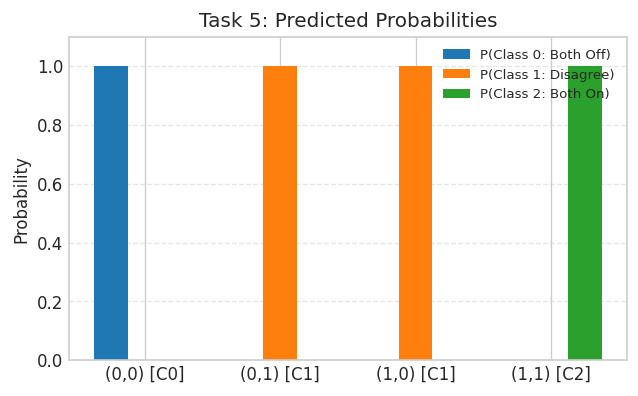

In [6]:
# Task 5: 3-Class Sensor Extension
import torch
import torch.nn as nn
import torch.optim as optim

X = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_3class = torch.tensor([0, 1, 1, 2], dtype=torch.long)

class Sensor3ClassNet(nn.Module):
    def __init__(self, hidden_dim=4):
        super().__init__()
        self.fc1 = nn.Linear(2, hidden_dim)
        self.activation = nn.Tanh()
        self.fc2 = nn.Linear(hidden_dim, 3)

    def forward(self, x):
        h = self.activation(self.fc1(x))
        return self.fc2(h)

torch.manual_seed(42)
model_3c = Sensor3ClassNet(hidden_dim=4)
criterion_3c = nn.CrossEntropyLoss()
optimizer_3c = optim.Adam(model_3c.parameters(), lr=0.05)

for epoch in range(1500):
    optimizer_3c.zero_grad()
    loss_3c = criterion_3c(model_3c(X), y_3class)
    loss_3c.backward()
    optimizer_3c.step()

logits_3c = model_3c(X).detach()
probs_3c = torch.softmax(logits_3c, dim=-1)
preds_3c = torch.argmax(probs_3c, dim=-1)

print(f"Final 3-Class Loss: {loss_3c.item():.6f}")
print(f"Predictions:       {preds_3c.tolist()} (Ground Truth: {y_3class.tolist()})")
print(f"All Correct?       {(preds_3c == y_3class).all().item()}\n")

print("Softmax Probability Vectors:")
for i in range(4):
    p_vec = probs_3c[i].numpy()
    print(f"Input {tuple(X[i].int().tolist())} -> P(y) = [C0: {p_vec[0]:.4f}, C1: {p_vec[1]:.4f}, C2: {p_vec[2]:.4f}] | Sum: {p_vec.sum():.6f}")

# Shift invariance check
logits_shifted = logits_3c + 100.0
probs_shifted = torch.softmax(logits_shifted, dim=-1)
max_diff = torch.max(torch.abs(probs_3c - probs_shifted)).item()
print(f"\nShift Invariance (Logits + 100) Max Abs Difference: {max_diff:.2e}")

### Diagnostic Analysis
- **Sum to One:** Softmax probabilities sum to $1.000000$ across all examples.
- **Shift Invariance:** Adding $100$ to logits produces identical probabilities ($\|p - p_{\text{shifted}}\|_\infty \approx 4.29 \times 10^{-10}$), confirming $\frac{e^{z_k+c}}{\sum e^{z_j+c}} = \frac{e^c e^{z_k}}{e^c \sum e^{z_j}} = \frac{e^{z_k}}{\sum e^{z_j}}$. Stable implementations subtract $\max_j z_j$ before exponentiating to prevent floating-point overflow.

### Think About It (Task 5)
**Question:** What stays mathematically the same and what changes when scaling to language models?  
**Answer:** The softmax normalization, cross-entropy loss, logit gradient form ($p - y$), and shift-invariance stabilization remain mathematically identical. What changes is the vocabulary scale ($V \sim 10^5$ classes), output projection size ($W \in \mathbb{R}^{V \times d}$), multi-layer transformer architecture, and distributed parallelization requirements.

---
# Reflection Questions

### 1. What did the XOR experiment demonstrate about the difference between depth and nonlinearity?
Depth of affine transformations collapses algebraically into a single affine transformation ($W_2 W_1 x + b' = W_{\text{eff}} x + b_{\text{eff}}$), providing no expansion in representational capacity. Nonlinearity bends and warps coordinate space, enabling non-convex decision regions to become linearly separable.

### 2. In your successful run, what evidence showed that backpropagation supplied a useful learning signal rather than merely a nonzero gradient?
The scalar BCE loss steadily decreased from $0.7152$ to $0.000083$, achieving 100% accuracy (4/4 correct). This confirms that gradient updates pointed in a consistent descent direction toward the task objective rather than random perturbation.

### 3. Why did identical/zero weight initialisation prevent the two hidden units from learning distinct features?
Identical weights cause both hidden units to compute identical activations and receive identical backpropagated error gradients. Because each update is identical, the units remain redundant copies for all iterations, reducing effective capacity to a single neuron that cannot solve XOR.

### 4. How did changing the hidden activation affect the gradient you observed? Distinguish the scientific explanation from the engineering observation.
- **Engineering:** Tanh produced the largest early gradient norm ($0.0618$) and converged to 100% accuracy, while Sigmoid ($0.00089$) and ReLU ($0.0017$) stalled under this initialization.
- **Scientific:** Sigmoid derivatives are bounded by $\le 0.25$, causing exponential gradient shrinkage. Tanh has unit derivative at origin and zero-centered outputs, supporting gradient flow. ReLU has zero gradient for negative pre-activations, deactivating units if initialized negatively.

### 5. Why must the output layer and loss be selected together according to the task?
The output layer must match the statistical support of the target distribution (Sigmoid for Bernoulli/binary; Softmax for Categorical/multiclass). Paired with cross-entropy, the activation derivative cancels the denominator of the loss derivative, yielding linear error residuals ($p - y$) and preventing vanishing gradients.

### 6. Give one example where the LLM improved your engineering productivity and one example where human verification was essential.
- **Productivity:** Generating boilerplate PyTorch architecture, training loop, and evaluation formatting.
- **Verification:** Catching and correcting naive `Sigmoid` + `BCELoss` code into numerically stable `BCEWithLogitsLoss`, and verifying convergence empirically rather than trusting syntactically correct code.

### 7. Which tests in this laboratory would you keep if the model were scaled up, and which would become too expensive?
- **Keep:** Loss tracking, metric monitoring, global gradient norm tracking ($\|\nabla_\theta \mathcal{L}\|_2$), and numerical stability checks (LogSumExp).
- **Too Expensive:** Exhaustive finite-difference gradient checks ($O(P)$ forward passes) and manual parameter row tracking or 2D decision contour plotting.